In [11]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
telco = pd.read_csv("../data/processed/telco_clean.csv")
print(telco.shape)
telco.head()

(7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,churn
0,Female,0,Yes,No,1,No,No,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


In [12]:
print(telco["churn"].mean())

0.2653698707936959


Contract
Month-to-month    0.427
One year          0.113
Two year          0.028
Name: churn, dtype: float64


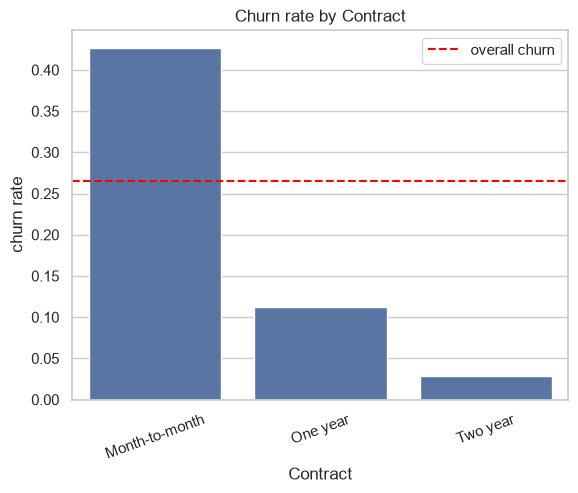

In [13]:
def churn_by(col):
    rates = telco.groupby(col)["churn"].mean().sort_values(ascending=False)
    print(rates.round(3))
    sns.barplot(x=rates.index, y=rates.values)
    plt.axhline(telco["churn"].mean(), color="red", linestyle="--", label="overall churn")
    plt.ylabel("churn rate")
    plt.title(f"Churn rate by {col}")
    plt.xticks(rotation=20)
    plt.legend()
    plt.savefig(f"../figures/telco_churn_by_{col}.png", bbox_inches="tight")
    plt.show()

churn_by("Contract")

InternetService
Fiber optic    0.419
DSL            0.190
No             0.074
Name: churn, dtype: float64


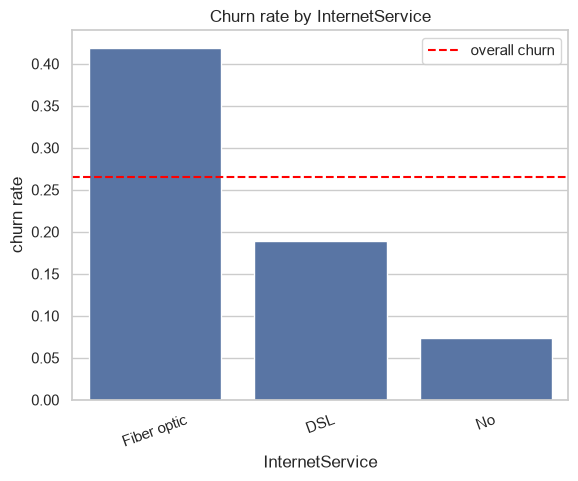

In [14]:
def churn_by(col):
    rates = telco.groupby(col)["churn"].mean().sort_values(ascending=False)
    print(rates.round(3))
    sns.barplot(x=rates.index, y=rates.values)
    plt.axhline(telco["churn"].mean(), color="red", linestyle="--", label="overall churn")
    plt.ylabel("churn rate")
    plt.title(f"Churn rate by {col}")
    plt.xticks(rotation=20)
    plt.legend()
    plt.savefig(f"../figures/telco_churn_by_{col}.png", bbox_inches="tight")
    plt.show()

churn_by("InternetService")

PaymentMethod
Electronic check             0.453
Mailed check                 0.191
Bank transfer (automatic)    0.167
Credit card (automatic)      0.152
Name: churn, dtype: float64


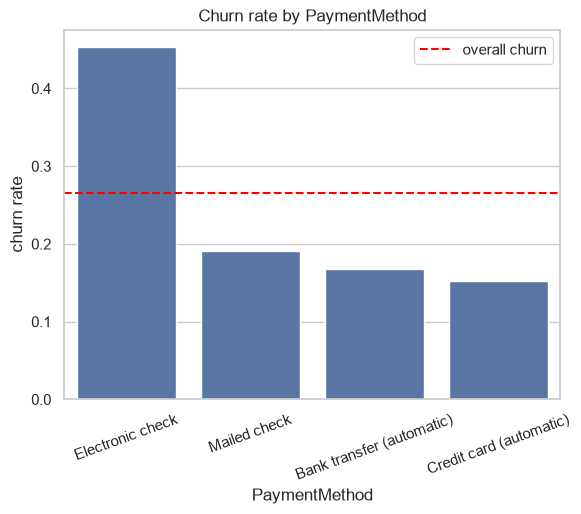

In [15]:
def churn_by(col):
    rates = telco.groupby(col)["churn"].mean().sort_values(ascending=False)
    print(rates.round(3))
    sns.barplot(x=rates.index, y=rates.values)
    plt.axhline(telco["churn"].mean(), color="red", linestyle="--", label="overall churn")
    plt.ylabel("churn rate")
    plt.title(f"Churn rate by {col}")
    plt.xticks(rotation=20)
    plt.legend()
    plt.savefig(f"../figures/telco_churn_by_{col}.png", bbox_inches="tight")
    plt.show()

churn_by("PaymentMethod")

TechSupport
No     0.312
Yes    0.152
Name: churn, dtype: float64


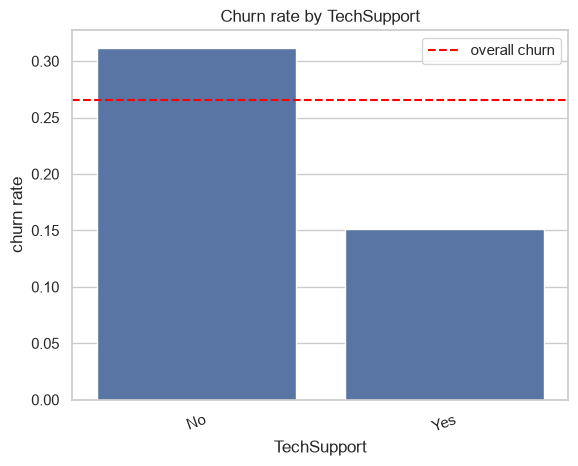

In [16]:
def churn_by(col):
    rates = telco.groupby(col)["churn"].mean().sort_values(ascending=False)
    print(rates.round(3))
    sns.barplot(x=rates.index, y=rates.values)
    plt.axhline(telco["churn"].mean(), color="red", linestyle="--", label="overall churn")
    plt.ylabel("churn rate")
    plt.title(f"Churn rate by {col}")
    plt.xticks(rotation=20)
    plt.legend()
    plt.savefig(f"../figures/telco_churn_by_{col}.png", bbox_inches="tight")
    plt.show()

churn_by("TechSupport")

SeniorCitizen
1    0.417
0    0.236
Name: churn, dtype: float64


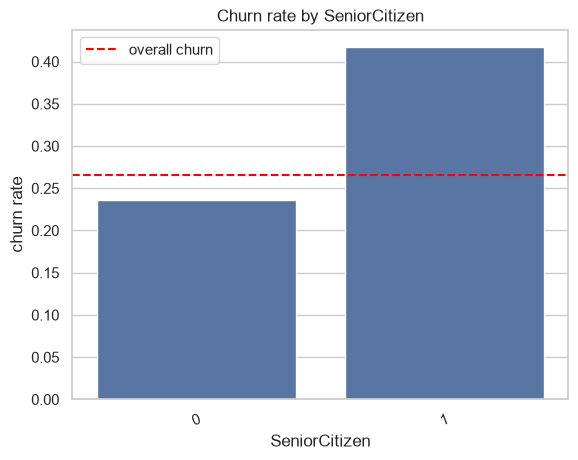

In [17]:
def churn_by(col):
    rates = telco.groupby(col)["churn"].mean().sort_values(ascending=False)
    print(rates.round(3))
    sns.barplot(x=rates.index, y=rates.values)
    plt.axhline(telco["churn"].mean(), color="red", linestyle="--", label="overall churn")
    plt.ylabel("churn rate")
    plt.title(f"Churn rate by {col}")
    plt.xticks(rotation=20)
    plt.legend()
    plt.savefig(f"../figures/telco_churn_by_{col}.png", bbox_inches="tight")
    plt.show()

churn_by("SeniorCitizen")

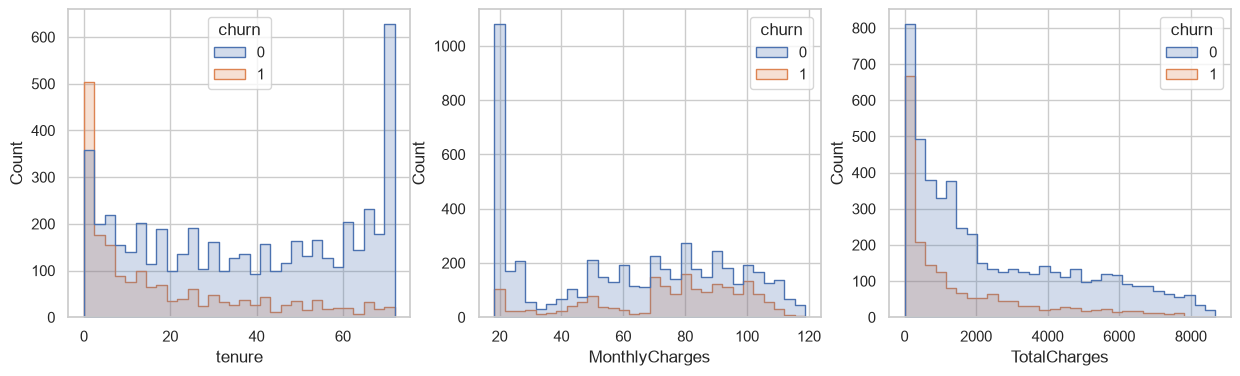

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.histplot(data=telco, x=col, hue="churn", bins=30, ax=ax, element="step")
plt.show()

In [19]:
telco["tenure_band"] = pd.cut(telco["tenure"], bins=[-1, 12, 24, 48, 72],
                              labels=["0-12", "13-24", "25-48", "49-72"])
print(telco.groupby("tenure_band", observed=True)["churn"].agg(["size", "mean"]).round(3))

             size   mean
tenure_band             
0-12         2186  0.474
13-24        1024  0.287
25-48        1594  0.204
49-72        2239  0.095


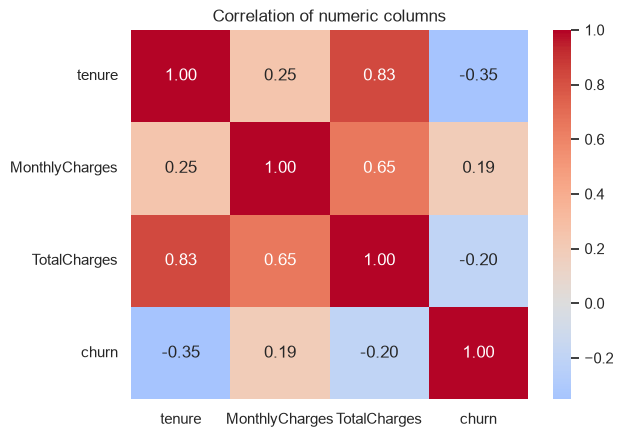

In [20]:
num = telco[["tenure", "MonthlyCharges", "TotalCharges", "churn"]]
sns.heatmap(num.corr(), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Correlation of numeric columns")
plt.savefig("../figures/telco_correlation.png", bbox_inches="tight")
plt.show()

Bank EDA

In [21]:
bank = pd.read_csv("../data/processed/bank_clean.csv")
print(bank.shape)
print(bank["churn"].mean())

(10000, 11)
0.2037


In [23]:
def churn_rate_plot(df, col, prefix):
    g = df.groupby(col, observed=True)["churn"].agg(["size", "mean"]).round(3)
    print(g)
    sns.barplot(x=g.index.astype(str), y=g["mean"])
    plt.axhline(df["churn"].mean(), color="red", linestyle="--", label="overall churn")
    plt.ylabel("churn rate")
    plt.title(f"Churn rate by {col}")
    plt.legend()
    plt.savefig(f"../figures/{prefix}_churn_by_{col}.png", bbox_inches="tight")
    plt.show()

           size   mean
Geography             
France     5014  0.162
Germany    2509  0.324
Spain      2477  0.167


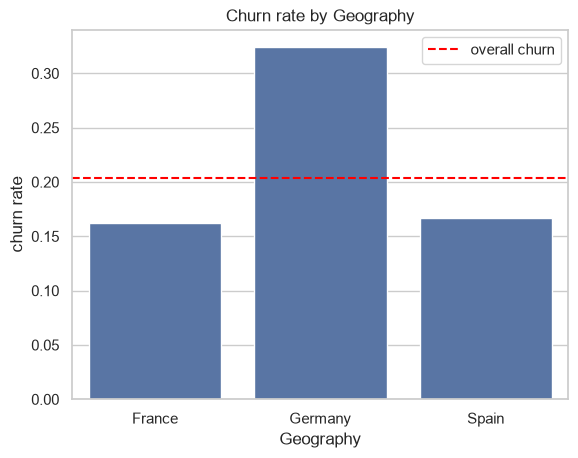

        size   mean
Gender             
Female  4543  0.251
Male    5457  0.165


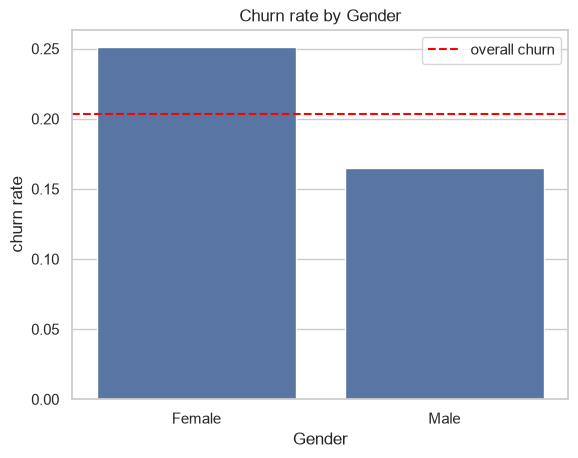

               size   mean
NumOfProducts             
1              5084  0.277
2              4590  0.076
3               266  0.827
4                60  1.000


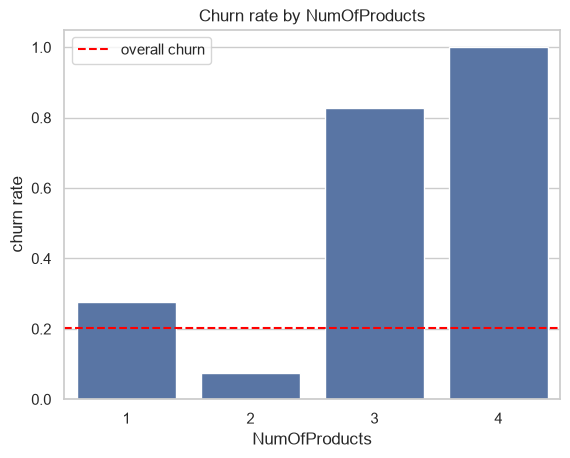

                size   mean
IsActiveMember             
0               4849  0.269
1               5151  0.143


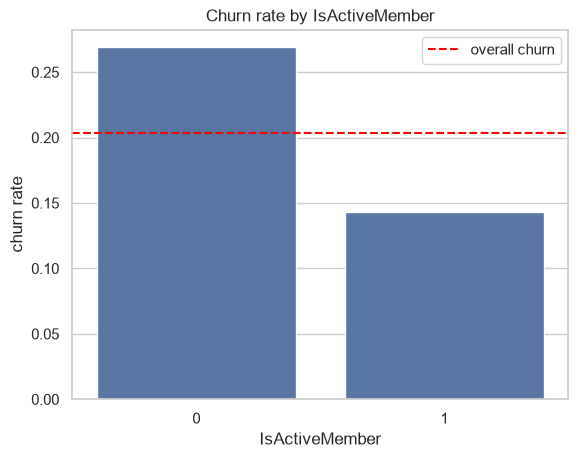

           size   mean
HasCrCard             
0          2945  0.208
1          7055  0.202


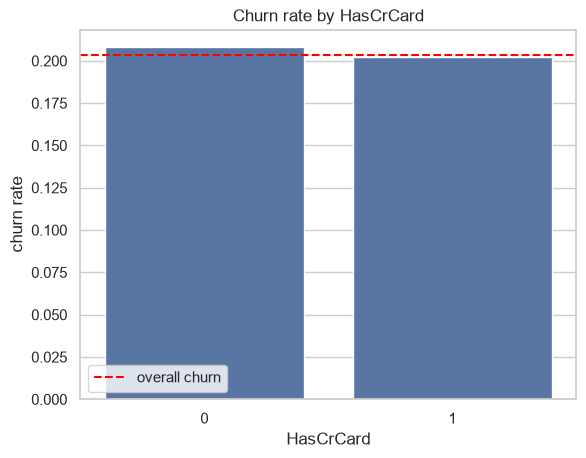

In [24]:
for c in ["Geography", "Gender", "NumOfProducts", "IsActiveMember", "HasCrCard"]:
    churn_rate_plot(bank, c, "bank")

          size   mean
age_band             
<=30      1968  0.075
31-40     4451  0.121
41-50     2320  0.340
51-60      797  0.562
60+        464  0.248


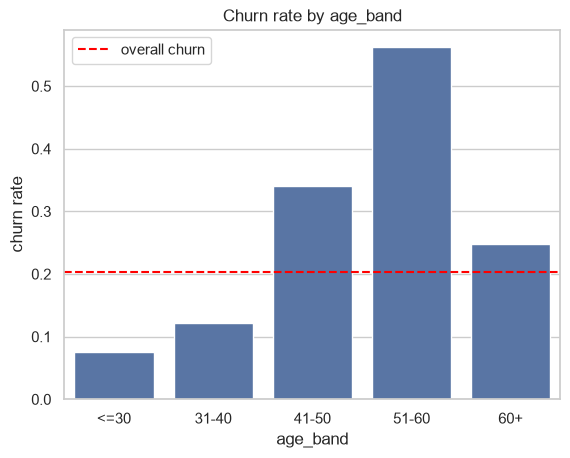

In [25]:
bank["age_band"] = pd.cut(bank["Age"], bins=[0, 30, 40, 50, 60, 100],
                          labels=["<=30", "31-40", "41-50", "51-60", "60+"])
churn_rate_plot(bank, "age_band", "bank")

             size   mean
has_balance             
False        3617  0.138
True         6383  0.241


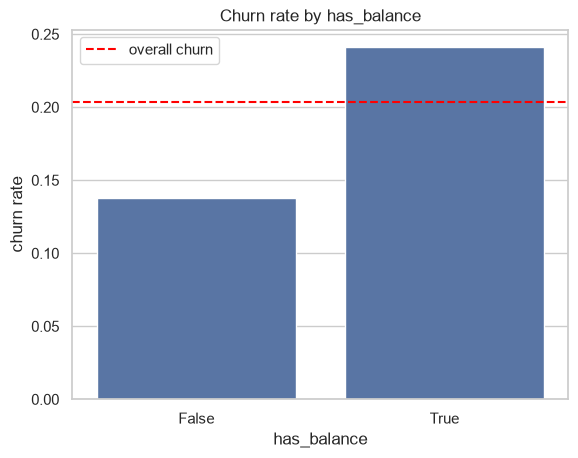

CreditScore       -0.03
Age                0.29
Tenure            -0.01
Balance            0.12
EstimatedSalary    0.01
churn              1.00
Name: churn, dtype: float64


In [26]:
bank["has_balance"] = bank["Balance"] > 0
churn_rate_plot(bank, "has_balance", "bank")

print(bank[["CreditScore", "Age", "Tenure", "Balance", "EstimatedSalary", "churn"]].corr().round(2)["churn"])